# 2. Repossession risk models

Question: for an open loan today, what is the probability that it is repossessed within 12 months?

Four approaches, from simple to flexible: a Markov chain, a logistic discrete-time hazard, an XGBoost
discrete-time hazard, and an XGBoost yes/no classifier. All synthetic data.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from repo_risk.cli import load_config
from repo_risk.features import NO_EVENT, PAYOFF, REPO, CHARGEOFF, outcome_within
from repo_risk.hazard import aalen_johansen, cumulative_incidence, expand_person_period
from repo_risk.train import MODEL_LABELS, MODEL_NAMES, load_bundle, month_ord

pd.options.display.float_format = "{:.4f}".format
cfg = load_config("configs/default.yaml")
lm = pd.read_parquet("data/processed/landmarks.parquet")
bundle = load_bundle(Path("models"))
metrics = json.loads(Path("reports/model_metrics.json").read_text())
lm.block.value_counts(dropna=False)

block
train     125674
test       79713
recent     77038
val        22460
None        6042
Name: count, dtype: int64

## Landmarks and what we know about each one

A landmark is an open loan at a month end. After the landmark, one of four things is recorded:
repossessed, paid off, charged off, or still open when the data ends (censored).
`months_observed` is how much follow-up the data has for that landmark.

In [2]:
lm[["loan_id", "landmark_date", "status", "months_on_book", "exit_code", "months_to_exit", "months_observed", "block"]].sample(6, random_state=3)

,loan_id,landmark_date,status,months_on_book,exit_code,months_to_exit,months_observed,block
273877,L0026408,2024-02-29,current,19,0,NaN,10,recent
262307,L0025299,2023-02-28,dpd_1_29,18,0,NaN,22,test
108540,L0010417,2020-11-30,current,17,2,46.0000,49,train
306242,L0029557,2021-09-30,current,11,1,30.0000,39,train
166,L0000017,2020-12-31,current,19,2,29.0000,48,train
209276,L0020157,2023-05-31,current,6,0,NaN,19,test


## Why censoring matters

Take the landmarks from 2024. Their 12-month windows run past the end of the data.
If I label each one "repossessed within 9 months: yes or no" using only what has been seen so far,
I undercount, because many of the "no" cases just have not had time yet.

In [3]:
recent = lm[lm.block == "recent"]
seen = recent.months_to_exit.notna() & (recent.months_to_exit <= recent.months_observed)
time = np.where(seen, recent.months_to_exit, recent.months_observed)
event = np.where(seen, recent.exit_code, NO_EVENT)
o = outcome_within(recent, 9)
pd.Series({
    "landmarks": len(recent),
    "share with less than 9 months of follow-up": 1 - o.complete.mean(),
    "naive rate (censored counted as 'no')": (o.event == REPO).mean(),
    "rate using only landmarks with 9 full months": (o.event[o.complete] == REPO).mean(),
    "Aalen-Johansen estimate (uses everything, handles censoring)": aalen_johansen(time, event, 9).cif.iloc[-1],
}).to_frame("value")

,value
landmarks,77038.0000
share with less than 9 months of follow-up,0.7266
naive rate (censored counted as 'no'),0.0213
rate using only landmarks with 9 full months,0.0346
"Aalen-Johansen estimate (uses everything, handles censoring)",0.0342


The naive number is well below the other two. The Aalen-Johansen estimate agrees with the
full-follow-up subset while using all the landmarks.

## Person-period data
Each landmark becomes one row per month it was followed. A censored loan just stops adding rows.
Training follow-up is cut at December 2022, even where later months are known, so nothing from the
test period reaches the model.

In [4]:
train = lm[lm.block == "train"].reset_index(drop=True)
pp = expand_person_period(train, 12, last_ord=month_ord(cfg["split"]["train_end"]))
print(f"{len(train):,} training landmarks -> {len(pp):,} person-month rows")
pp.y.map({NO_EVENT: "stayed open", REPO: "repossessed", PAYOFF: "paid off", CHARGEOFF: "charged off"}).value_counts()

125,674 training landmarks -> 1,130,822 person-month rows


y
stayed open    1117073
paid off          9190
repossessed       3201
charged off       1358
Name: count, dtype: int64

## The competing-risks arithmetic
The hazard models give a probability for each of the four outcomes in each month. Repossession
within 12 months adds up "still open so far" times "repossessed this month". Payoff and charge-off
take loans out of the pool. Ignoring them overstates repossession a little.

In [5]:
example = lm[(lm.block == "test") & (lm.status == "dpd_60_89")].head(1)
hz = bundle.xgb_hazard.hazards(example)
cif = cumulative_incidence(hz)
table = pd.DataFrame(hz[0], columns=["stay open", "repossessed", "paid off", "charged off"], index=range(1, 13))
table["cumulative repossession"] = cif["repo"][0]
print("One account at 60-89 days past due, months 1 to 12 after the landmark:")
display(table)
print(f"Correct 12-month probability:                {cif['repo'][0, -1]:.4f}")
print(f"If other exits are ignored, 1 - prod(1 - h): {1 - np.prod(1 - hz[0, :, 1]):.4f}")

One account at 60-89 days past due, months 1 to 12 after the landmark:


,stay open,repossessed,paid off,charged off,cumulative repossession
1,0.9889,0.0093,0.0015,0.0004,0.0093
2,0.9670,0.0300,0.0023,0.0007,0.0389
3,0.9541,0.0400,0.0038,0.0021,0.0771
4,0.9454,0.0465,0.0042,0.0040,0.1195
5,0.9456,0.0448,0.0048,0.0049,0.1581
6,0.9644,0.0250,0.0055,0.0052,0.1785
7,0.9643,0.0244,0.0068,0.0045,0.1977
8,0.9734,0.0173,0.0059,0.0034,0.2108
9,0.9831,0.0090,0.0052,0.0028,0.2174
10,0.9848,0.0081,0.0053,0.0017,0.2233


Correct 12-month probability:                0.2332
If other exits are ignored, 1 - prod(1 - h): 0.2386


## What the logistic hazard learned
Coefficients are on standardized features and are relative to "stay open". Positive means the exit is more likely.

In [6]:
coef = bundle.logit_hazard.coefficients().rename(columns={REPO: "repossessed", PAYOFF: "paid off", CHARGEOFF: "charged off"})
feat = coef[~coef.index.str.startswith("month_")]
feat.loc[feat["repossessed"].abs().sort_values(ascending=False).index[:12]]

,repossessed,paid off,charged off
payments_behind,0.4146,-0.1507,0.9063
pti,0.2796,0.0218,0.2270
pay_ratio_3m,-0.2460,-0.0545,-0.1867
servicing_group_C,-0.1986,0.0223,0.0680
apr,0.1983,-0.0075,0.0107
months_since_30plus,-0.1932,-0.0131,0.0121
months_on_book,-0.1647,-0.2918,-0.2854
max_dpd_6m,0.1608,-0.0332,0.1201
balance_ratio,-0.1425,-0.8658,-0.1620
max_dpd_ever,-0.1176,-0.0329,-0.0905


In [7]:
coef[coef.index.str.startswith("month_")].T.round(2)

,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
repossessed,-0.0400,0.1200,0.4400,0.7000,0.6400,0.8000,0.9300,0.7700,0.8000,0.8500,0.6100
paid off,0.3700,0.4600,0.4600,0.5400,0.6100,0.6100,0.6700,0.7500,0.7600,0.7900,0.8800
charged off,-0.5900,-0.0100,0.0900,0.3600,0.7000,0.5600,0.6600,0.8200,0.6100,0.6800,0.6800


For repossession, `payments_behind` leads, followed by PTI and how much of the amount due was paid
recently. The servicing group indicators are negative: groups B and C repossess more slowly than A.
That is a servicing effect, not a borrower effect, and the model needs it to be right.

Two things I did not expect. `repo_assigned` gets a small coefficient, and `days_past_due` is
slightly negative. Both overlap heavily with `payments_behind`, so the model splits the credit
between them and single coefficients stop meaning much. This is the usual problem with reading a
linear model that has correlated inputs.

The month indicators are the baseline hazard. For repossession it climbs over the first several
months after the landmark. Most landmarks are current accounts, and a current account needs time
to fall behind before it can be repossessed.

## Test results
Test landmarks are from 2023. Every 12-month window ends by December 2024, so each landmark has a
known answer and ordinary metrics are valid. Loans that paid off in the window are known "no" cases.

,ROC-AUC,PR-AUC,Brier,mean predicted,observed
Markov chain,0.7701,0.2442,0.0348,0.0371,0.0430
Logistic hazard,0.8239,0.3244,0.0344,0.0324,0.0430
XGBoost hazard,0.8242,0.3298,0.0340,0.0351,0.0430
XGBoost direct,0.8232,0.3254,0.0342,0.0347,0.0430


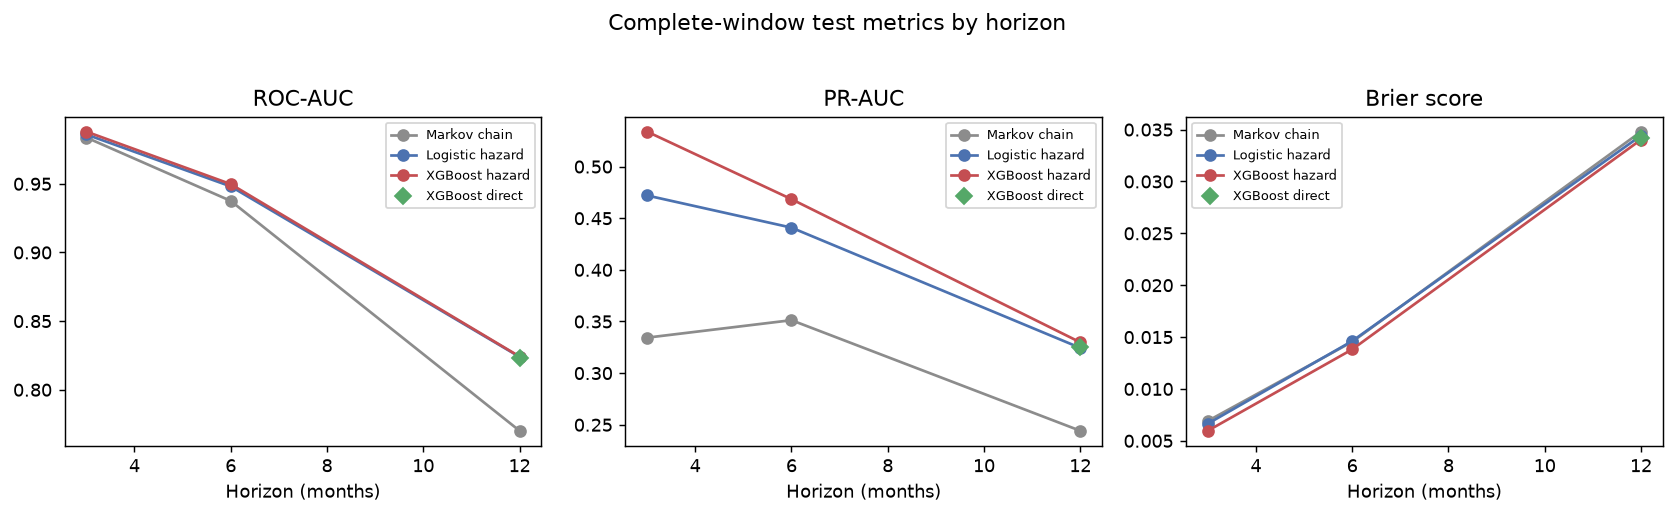

In [8]:
rows = {}
for m in MODEL_NAMES:
    b = metrics["complete_window_test"]["12"][m]
    rows[MODEL_LABELS[m]] = {"ROC-AUC": b["roc_auc"], "PR-AUC": b["pr_auc"], "Brier": b["brier"],
                             "mean predicted": b["mean_predicted"], "observed": b["event_rate"]}
display(pd.DataFrame(rows).T)
display(Image("figures/metrics_by_horizon.png"))

Three things stand out.

1. The three feature-based models are tied at 12 months, and all clearly beat the Markov chain,
   which only knows the current status.
2. At 3 months everything has a very high ROC-AUC, the Markov chain included. Short-horizon
   repossession is almost entirely "who is already deep in delinquency". PR-AUC still separates the
   models there, and the gap in ROC-AUC opens up at 12 months.
3. Every model predicts too few repossessions for 2023: about 3.2% to 3.7% against 4.3% observed.

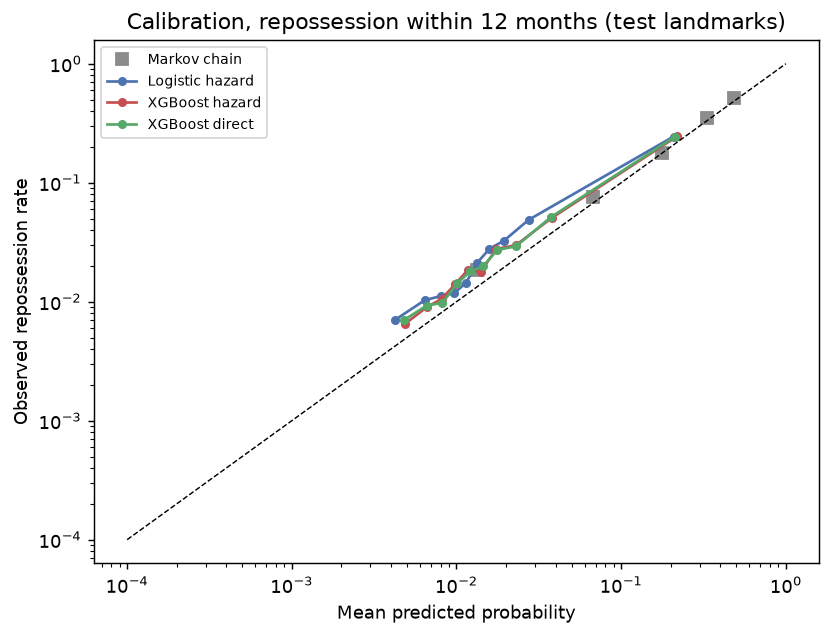

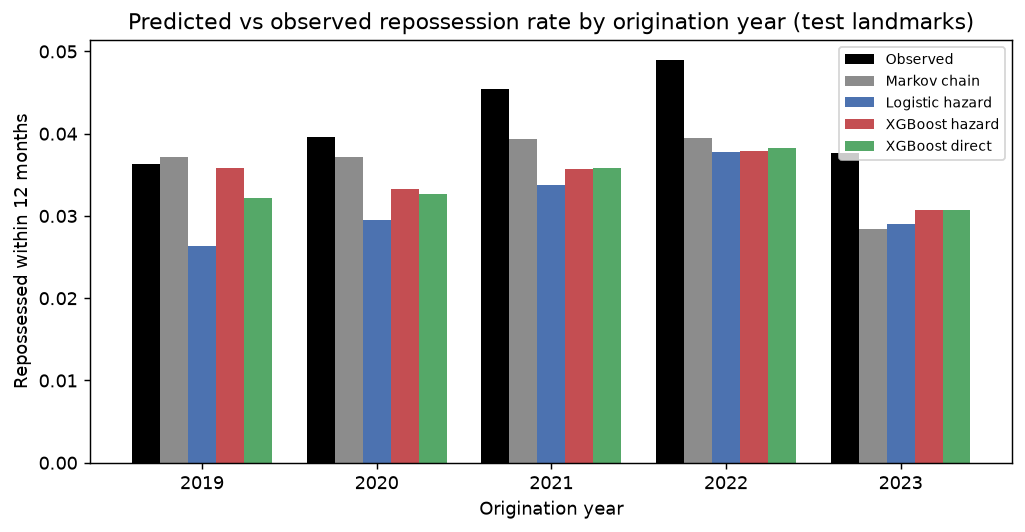

,n,observed,markov,logit_hazard,xgb_hazard,xgb_direct
status_label,,,,,,
current,67018,0.0186,0.0134,0.0126,0.0137,0.0140
dpd_1_29,7196,0.0757,0.0678,0.0335,0.0567,0.0574
dpd_30_59,2886,0.1784,0.1768,0.1413,0.1439,0.1279
dpd_60_89,1362,0.3473,0.3338,0.2976,0.3182,0.3448
dpd_90_plus,1251,0.5164,0.4854,0.5452,0.5031,0.4576


In [9]:
display(Image("figures/calibration_12m.png"))
display(Image("figures/cohort_predicted_vs_observed.png"))
pd.DataFrame(metrics["by_status"]).set_index("status_label")

The shortfall is across the board, and largest for accounts that were current or 1-29 days past due
at the landmark. Those are the accounts whose repossession needs a new delinquency to start, and
delinquency ran higher in 2023-24 than in the training years. The training period also contains
the 2020 servicing pause, which pulls the learned repossession hazard down.

This is what an out-of-time test is for. A random split would have hidden it. In practice the fix
is regular recalibration and monitoring, not a cleverer model.

The logistic hazard is also noticeably low for the 1-29 bucket. A linear model has trouble with
the jump in risk between "current" and "a little behind". The tree models handle that better.

## The most recent landmarks, with censoring handled properly

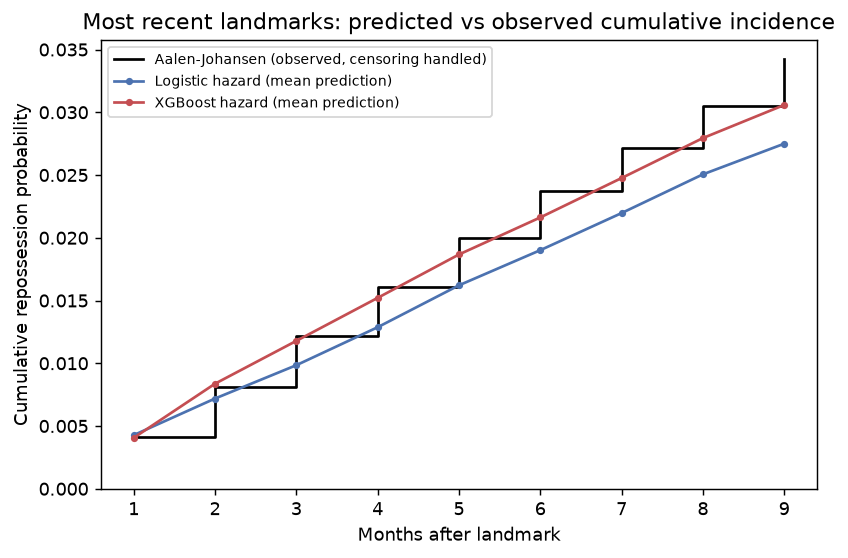

,n,aalen_johansen,logit_hazard,xgb_hazard
tercile,,,,
low,25679,0.0036,0.0056,0.0039
middle,25679,0.0076,0.0089,0.0073
high,25680,0.0922,0.0680,0.0805


In [10]:
display(Image("figures/censored_check.png"))
pd.DataFrame(metrics["censored_check"]["by_risk_tercile"]).set_index("tercile")

For 2024 landmarks the observed curve is the Aalen-Johansen estimate. The models rank well (the top
third carries nearly all the risk) and again sit a little under the observed level.

## Hazard model or direct classifier?

On the 12-month test they score the same. The differences are practical:

* The direct classifier had to drop every training landmark from 2022, because their 12-month labels
  were not complete by the training cutoff. The hazard models used them.

In [11]:
log = json.loads(Path("models/training_log.json").read_text())
pd.Series({"training landmarks": log["direct_rows"]["train"] + log["direct_rows"]["train_dropped_incomplete"],
           "dropped by the direct classifier (window not complete)": log["direct_rows"]["train_dropped_incomplete"],
           "person-month rows used by the hazard models": log["person_period_rows"]["train"]}).to_frame("count")

,count
training landmarks,125674
dropped by the direct classifier (window not complete),50224
person-month rows used by the hazard models,1130822


* One hazard model gives every horizon from 1 to 12 months, plus the payoff and charge-off
  probabilities. The direct classifier answers one question for one horizon.
* The direct classifier is simpler to build and far cheaper to fit.

## What none of these models can do

* They predict repossession **under the servicing policies in the data**. Different assignment
  rules, capacity or legal constraints would change the outcome with no change in borrower behavior.
* The label is selected. A loan is repossessed only if the servicer chose to pursue it and found the
  vehicle. Loans that were charged off because the vehicle was never found look like "no
  repossession", though the borrower behaved the same way.
* They are not causal. They cannot say what would happen to an account if it were treated differently.